# 最近三个阶段，分别做了什么实验？

**整理日期：2026年10月12日｜重点范围：9月30日至10月10日的已完成实验。**

这份笔记本用来回顾研究过程。先讲每一阶段在干什么，再讲为什么一轮接一轮地改，最后看最近一轮的实数。
不用先读代码；图表已经算好。想核对计算时，再展开代码，或在 Jupyter 中从上到下运行。

先记住三件事：

| 阶段 | 实际要做的决定 | 当前最值得记住的结果 |
|---|---|---|
| 第一阶段：覆盖规划 | 波束摆在哪里、用多少束、哪些飞机归哪束 | 已找到可用的规则/示范方法；最近两组PPO仍没超过强对照 |
| 第二阶段：频率分配 | 每束占哪一段频率、占多少槽 | 从贪心初解出发、让SAC选择局部修改，得到目前较明确的平均收益 |
| 第三阶段：功率细调 | 频率槽固定后，每束具体给多少瓦 | 连续优化能改善分配；已有SCA之后继续细调，收益很小、时间更长 |

**这是研究分工，不代表三个阶段已经用同一批场景完整串起来验收。**
第一阶段的几何覆盖也不等于所有飞机的通信需求都得到满足。

**10月12日的方向更新：你已不再强制第一阶段走DRL，可以考虑纯AI或AI＋优化。**
下文回顾的PPO/BC实验仍按当时条件解释；掩码布局重构、AI辅助搜索等新方向目前只讨论过，尚未实施，不能算新增实验成果。

阅读顺序：①先认指标 → ②覆盖怎么改 → ③频率怎么分 → ④功率怎么调 → ⑤目前能说到哪一步。

## 先把几个容易混的词讲清楚

- **基线**：拿来比较的方法，比如贪心规则、随机搜索。运行它们做考核，不等于训练了模型。
- **PPO / SAC**：这里用到的两种强化学习算法。第一阶段主要用PPO，第二阶段主要用SAC。它们学的是怎样选动作。
- **BC（行为克隆）**：照着教师给出的动作学习。它也是学习方法，但没有PPO那种与环境交互、按奖励更新的过程。
- **CV（负载变异系数）**：看波束之间的需求有多不均匀，越低越均匀。不同实验的束数、场景和“主体束”口径不同，不能直接把各组CV排总榜。
- **SI（需求满足率）**：每束算“最终容量÷需求”，超过1按1算，再对目标波束平均。第二、三阶段包含未服务束和后续干扰。它不等于“满足了这么大比例的飞机”，也不等于总承载流量比例。
- **SGM（供需匹配程度）**：另一把尺子，既看不够用，也看给得过多。因此SI提高时，SGM可能下降。
- **母场景**：一个原始航空快照。从它变出低/中/高需求，或不同束数，仍有共同来源。100母×3档是300条条件记录，不能说成300个独立母场景。
- **直接结果 / 完整B**：前者是第二阶段刚分完的结果；后者是固定这些频率槽，再做统一的连续功率优化。比学习贡献时，两边都应当处于同一处理阶段。

还有一个代号重名：**第一阶段I0＝原始布局不调整；第二阶段I0＝SAC多步局部改进**。下文会带着阶段或中文名称写。

例如SI从90%升到93%，是提高 **3个百分点**；不是提高3%，也不表示每个场景都进步了。

### 计算准备（只读旧结果）

下面的代码只读取本地保存的结果、重新汇总和画图。不会加载策略去执行环境，也不会训练或追加评价。
第三阶段图表默认展示3000 W总预算；把 `POWER_BUDGET` 改成 `"initial"`，可查看“每个初解自身总功率作上限”的另一口径。
这两个口径都已经有保存结果。

In [1]:
from pathlib import Path
import hashlib, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown

# 在项目根目录或 docs/资料 启动都可以；其他位置可直接修改 ROOT。
candidates = [Path.cwd(), *Path.cwd().parents, Path('D:/paper')]
ROOT = next(p for p in candidates if (p / 'EXPERIMENT_STATUS.md').is_file())
OUT = ROOT / 'outputs/research_overview_20261012'
(OUT / 'figures').mkdir(parents=True, exist_ok=True)
POWER_BUDGET = 'total'  # total：3000 W；initial：各初解自己的总功率上限
assert POWER_BUDGET in ('total', 'initial')
POWER_LABEL = {'total': '3000 W总预算', 'initial': '初解自身总功率上限'}[POWER_BUDGET]
SOURCES = {'s1': 'outputs/experiments/first_stage_s1_d12a_20261010/analysis/final_report_verified/per_scene.csv', 's1_published': 'outputs/experiments/first_stage_s1_d12a_20261010/analysis/publication/overall_100_mothers.csv', 's2': 'outputs/experiments/sac_routes_s2p19_20261007/analysis/final_report_material/per_scene.csv', 's3_p02': 'outputs/experiments/stage3_all_routes_20261003/report_20261003/method_summary.csv', 's3_p02_time': 'outputs/experiments/stage3_all_routes_20261003/report_20261003/timing_summary.csv', 's3_p03': 'outputs/experiments/stage3_si_priority_20261003/report_20261003/method_summary.csv', 's3_p03_time': 'outputs/experiments/stage3_si_priority_20261003/report_20261003/timing_summary.csv'}
EXPECTED_SHA = {'s1': 'd444cc498cb495d191eb1762c05774f11aa250dacd9b9122182dbc9ed86b3249', 's1_published': '2c678379a6f2e640e9b57d9f9dbbf6b6ad946ca8aabc1adb41b7d683a917c6ba', 's2': '1a76c4c3f362edfe87292bce8c13f8aa766cf611a2c1593253b9485a222008b9', 's3_p02': '41e2840be436b300c942f376ed91eb8109b90bd8da0ef63f7ceeabae6257bdb4', 's3_p02_time': '9436834ef5b306b6055fbdb737abb6a5b72505ead18cf7722656334251ea952f', 's3_p03': 'bd29530ed2b78c8b091783f852df83df3fa062dcfa3a42cf15c5eadfdff5a702', 's3_p03_time': '0a6f550e6ba5bd9ba920c49932e69ed00c73aacf749600091214eb0678a19fc5'}

def read_result(key):
    path = ROOT / SOURCES[key]
    assert hashlib.sha256(path.read_bytes()).hexdigest() == EXPECTED_SHA[key], f'来源已变化：{path}'
    return pd.read_csv(path, encoding='utf-8-sig')

def table(frame, decimals=3):
    display(HTML(frame.to_html(index=False, float_format=lambda x: f'{x:.{decimals}f}', na_rep='未记录', border=0)))

plt.rcParams.update({'font.sans-serif': ['Microsoft YaHei', 'SimHei', 'DejaVu Sans'],
    'axes.unicode_minus': False, 'font.size': 11, 'axes.spines.top': False,
    'axes.spines.right': False, 'figure.dpi': 120, 'savefig.dpi': 160})
BLUE, ORANGE, GREEN, GRAY = '#0072B2', '#D55E00', '#009E73', '#777777'
def save_show(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / 'figures' / f'{name}.png', bbox_inches='tight')
    fig.savefig(OUT / 'figures' / f'{name}.pdf', bbox_inches='tight')
    plt.show()
    plt.close(fig)
print('已定位项目；接下来只读7份既有CSV。图表统计种子：不适用（未做随机重采样）。')

已定位项目；接下来只读7份既有CSV。图表统计种子：不适用（未做随机重采样）。


## 一、第一阶段：先把波束覆盖和负载分配做好

这个阶段的难点是：把所有飞机圈进波束，并不代表各束需求就均匀。一个波束可能很忙，另一个却很空。
你先试移动现有波束，后来改为重构区域、拆束和合束，再检查学习到底有没有额外作用。

### 前面几轮为什么没有停下来

| 实验 | 做了什么 | 看到了什么 |
|---|---|---|
| **S1-01，9月30日** | 固定100束，对比规则/聚类初解、搜索、PPO微调、从空白构造；3个PPO各409600步，另4个基线 | 聚类加搜索较均衡；两个PPO微调没有超过各自的搜索对照。从空白构造虽有较低CV，但可行景只有82/100 |
| **S1-02 A，10月4日** | 先补覆盖，再改飞机归属，再试四向调位；这4条都不训练 | 严格双100%覆盖从35/100升到92/100，主体CV从0.7926降到0.5491，但完整均衡目标仍0/100 |
| **S1-02 B，10月4日** | 从共同初解比较三种动作菜单；3个PPO各409600步，对照同菜单搜索 | 只有双束动作PPO的“保留最好布局”有很小的平均CV优势；它的原终态反而弱于搜索。完整目标仍0/100 |
| **S1-03原版，10月5日** | 让PPO选区域重构动作 | 65536步机制检查后停止；同时查出距离矩阵缓存没更新。没有完成原定500条独立考核，旧权重不能当修复版终点 |
| **S1-03-R1，10月5日** | 修好缓存，从零完整训练262144步；与同重构器规则、随机、搜索比较 | PPO主体CV为0.6022，搜索为0.6637，100景中71景CV更低。这一组确有局部收益；但严格双100%覆盖仍93/100，完整均衡目标仍0/100 |

这里的“双100%”指当时报告同时要求的飞机数覆盖和需求覆盖都达100%。这几组的“主体束CV”不等同于后面可变束数实验的全部束CV。
S1-03原版已用掉的65536步保留记账；修复版262144步是另一次从零训练，两次合计327680步。

来源：[七组对照](../第一阶段/实验报告/02_七组覆盖规划独立场景对照.md)、[A阶段](../第一阶段/实验报告/04_覆盖优先与主体负载均衡A阶段对照.md)、[B阶段](../第一阶段/实验报告/05_动作空间与PPO负载均衡B阶段对照.md)、[停止诊断](../第一阶段/实验报告/06_区域重构PPO机制检查与停止诊断.md)、[修复版](../第一阶段/实验报告/07_区域重构PPO修复版共同考核.md)。

### 接着放开束数：十二条路线一起看（S1-V10，10月9日）

这次不再固定100束，允许最多200束；每个场景都要求所有飞机被覆盖，同时看低、中、高需求。
十二条路线里，**只有R08、R09是新训练的PPO**，各262144次决策；其他是构造、搜索、优化或时序规则。

- **R04**：规则式拆合/修整路线，需求CV约0.478，逐机承载约85.21%，两项兼顾得较好。
- **R05**：理想化可变宽度路线，CV更低，约0.375，但逐机承载只有约75.37%。负载看起来更均匀，实际模型服务反而差一些。
- **R08 / R09**：两个PPO的CV约0.831 / 0.936，逐机承载约73.70% / 75.30%，没有综合优势。R08完成训练，但验证时常直接停在初解；不要把“选了停止动作”误读成训练没做完。
- **R12动态尝试**：后续300帧都回退重建，没有证明能有效沿用上一时刻布局。

静态考核是100母×3档×12路线＝3600条；时序考核另有20条母序列、720条方法记录。
静态结果全部几何覆盖，实际输出38–111束，**没有证据说明112–200束输出也已经测过**。
这次不同路线的初解、菜单和预算并不一致，所以后来又做了一组条件更统一的比较。

来源：[十二路线正式报告](../第一阶段/实验报告/08_可变波束全覆盖与负载均衡十二路线对照.md)。

### 最近一轮：把规则、模仿和强化学习分开比（S1-D12A，10月10日）

所有方法使用同一可行初解、同一拆合菜单、同一目标和几何计算预算，固定0.5°宽度。
这样更容易回答：改善来自初解和教师，还是来自PPO后续学习？

| 代号 | 直白理解 | 是否学习 |
|---|---|---|
| I0 | 初始布局直接交卷 | 否 |
| H1 | 每次挑眼前最合算的改动 | 否 |
| H2 | 多往后看一步，再挑改动 | 否 |
| BC | 模仿规则教师的选择 | 是，但不是强化学习 |
| P0 | 从零训练PPO来选改动 | 是，PPO |
| P1 | 先用BC，再接着训练PPO | 是，BC＋PPO |

P0、P1各训练262144次决策，训练种子都为51001。独立考核100母、每母3档需求，6种方法共1800条。
教师19994条标签、BC的1580次更新单独记账。

下面直接从保存的逐场景CSV重算。先在同一个母场景内合并3档，再对100母平均。

In [2]:
s1 = read_result('s1')
assert len(s1) == 1800 and not s1.duplicated(['method','dataset_index','demand_multiplier']).any()
assert s1.groupby(['method','dataset_index']).size().eq(3).all()
assert s1.groupby('method')['dataset_index'].nunique().eq(100).all()
order1 = ['I0','H1','H2','BC','P0','P1']
names1 = {'I0':'不调整 I0','H1':'即时规则 H1','H2':'两步搜索 H2','BC':'模仿教师 BC','P0':'从零PPO P0','P1':'BC后PPO P1'}
metrics1 = ['load_cv','aircraft_tdma_carried_fraction','total_seconds','algorithm_plus_best_physical_seconds']
s1_mother = s1.groupby(['method','dataset_index'])[metrics1].mean()
s1_mean = s1_mother.groupby('method').mean().reindex(order1)
published = read_result('s1_published').set_index('method').reindex(order1)
assert np.allclose(s1_mean.load_cv, published.load_cv_mean, atol=1e-10)
s1_table = pd.DataFrame({'方法':[names1[x] for x in order1], '负载CV↓':s1_mean.load_cv.values,
    '相对H1的CV变化/%':(s1_mean.load_cv/s1_mean.loc['H1','load_cv']-1).values*100,
    '逐机承载/%↑':s1_mean.aircraft_tdma_carried_fraction.values*100})
table(s1_table, 4)

方法,负载CV↓,相对H1的CV变化/%,逐机承载/%↑
不调整 I0,0.8348,68.8673,73.2319
即时规则 H1,0.4943,0.0000,84.4570
两步搜索 H2,0.5348,8.1915,81.0929
模仿教师 BC,0.4758,-3.7500,84.7159
从零PPO P0,0.5059,2.3494,84.5252
BC后PPO P1,0.5263,6.4745,84.3962


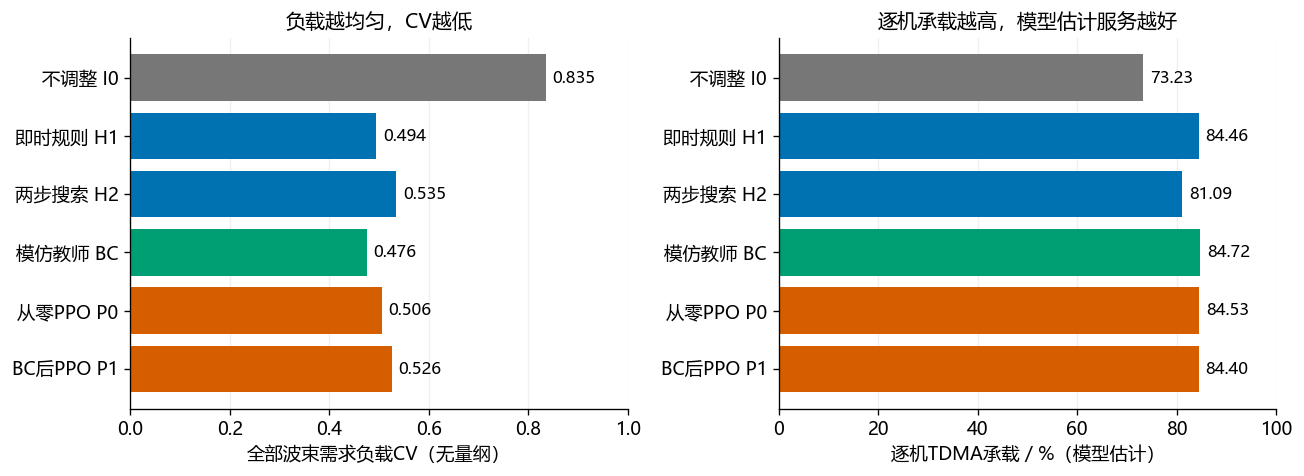

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.1))
colors = [GRAY,BLUE,BLUE,GREEN,ORANGE,ORANGE]
for ax, values, title, xmax, fmt in [
    (axes[0], s1_mean.load_cv, '负载越均匀，CV越低', 1.0, '.3f'),
    (axes[1], s1_mean.aircraft_tdma_carried_fraction*100, '逐机承载越高，模型估计服务越好', 100, '.2f')]:
    bars = ax.barh([names1[x] for x in order1], values, color=colors)
    ax.invert_yaxis(); ax.set_xlim(0,xmax); ax.set_title(title, fontsize=12)
    ax.bar_label(bars, labels=[format(v,fmt) for v in values], padding=4, fontsize=10)
    ax.grid(axis='x', alpha=.18); ax.set_axisbelow(True)
axes[0].set_xlabel('全部波束需求负载CV（无量纲）')
axes[1].set_xlabel('逐机TDMA承载 / %（模型估计）')
save_show(fig, '01_s1_latest_quality')

**这张图怎么读：**P0、P1确实改变了布局，分别在92/86个母场景降低代理目标J；这不表示所有场景的实际承载都改善。换成即时规则H1比较，两个PPO的CV反而高2.35%、6.47%。
BC的CV最低，P1在BC后继续强化学习没有带来总体收益。

逐机承载也没有拉开明显差距：H1约84.46%，P0约84.53%，P1约84.40%。这些是通信模型的估计，不是飞机真实测速结果。
六法全部几何覆盖，实际40–111束；同项目几何和代数回放通过，但并非另写一套RF模型独立验证。

**为什么不能说“至少更快就算成功”？**事前的效率条件还要求CV最多退步2%。P0是2.35%，已经超出；不能事后把门槛改宽。
下面同时列时间。它包括初解生成和一次发布布局的物理核验；另列完整记录工作流，后者还有多布局审计，不能混为同一个时间。

In [4]:
rows = []
for method in order1:
    part = s1_mother.loc[method]
    t = part.algorithm_plus_best_physical_seconds
    rows.append([names1[method],t.mean(),t.median(),t.quantile(.95),part.total_seconds.mean()])
table(pd.DataFrame(rows, columns=['方法','算法＋一次核验均时/s','中位/s','P95/s','完整记录工作流均时/s']), 3)

方法,算法＋一次核验均时/s,中位/s,P95/s,完整记录工作流均时/s
不调整 I0,0.456,0.497,0.723,0.456
即时规则 H1,2.285,2.724,3.744,2.571
两步搜索 H2,2.244,2.600,3.603,2.526
模仿教师 BC,1.095,1.270,1.744,1.447
从零PPO P0,1.101,1.286,1.738,1.426
BC后PPO P1,1.075,1.283,1.738,1.350


这组已经完成训练、考核和归档；“没有达到科学门槛”不是“任务还没跑完”。
目前第一阶段可以说：一些学习策略确实会改布局，修复版区域重构PPO在自己的那组对照中有收益；
但最近统一条件下，PPO还没证明超过BC或强规则。指向、宽度和动态业务的完整目标也没有完成。
按10月12日的最新决定，后续无需为了符合旧DRL定位而强加PPO；应看AI本身能否在同条件下改善布局或提高求解效率。
这项方向调整没有改写上述历史成绩，也没有启动新的训练或评价。

来源：[S1-D12A正式报告09](../第一阶段/实验报告/09_R04引导的DRL覆盖A阶段对照.md)。

## 二、第二阶段：从“从头分配”转向“改一个已有好解”

这个阶段给定波束布局，处理频率资源与干扰。历史方法还让模型选离散功率档位；当前主线收束为：
**学习选择频率起点、槽数等离散结构，初始功率由规则给，最终连续功率交给数学优化。**
历史方法按原配置保留，不能倒过来说它们一直都采用现在的分工。

### 最近四组在追什么问题

| 实验 | 改了什么、实际训练多少 | 结果与后续原因 |
|---|---|---|
| **G11，10月1–3日** | 分开比较温度系数、分配记忆、干扰图；9个新模型，T组2个各15万步，M组4个/G组3个各40万步 | T0的SGM较好、资源较省，但SI不是最高；长记忆没有稳定提高SI，显式干扰边有局部收益。你综合选择T0作第三阶段历史起点 |
| **S2-P17，10月4日起** | V0只用100束训练，V1用50–200束混合训练；同数量感知结构，各40万步 | 留出束数上，V1比V0直接SI高约0.722百分点，功率优化后高约0.279；但贪心＋同样优化仍更强 |
| **S2-P18，10月6–7日** | V2改奖励/组号/回放，V3改长回合学习处理，G0改逐束表示；3个各40万步 | V2有改进，但同440景最终SI约92.3624%，仍低于贪心的93.3354%；V3、G0更弱。继续微调构造式策略还没超过贪心 |
| **S2-P19，10月7–9日** | C0/C1继续从空白构造；I0改成从贪心初解做局部修改 | I0在新场景里得到更明确的平均收益；C0/C1仍没有超过贪心，所以下面重点看这组 |

P18曾出现评价口径混比，10月7日已补审计更正：V2通过了大N质量及小N保护两项门槛；并非“全部门槛失败”。
但这不等于总体超过贪心，另一项联合机制检查仍待完整核查。这里保留更正，不沿用报告正文里的旧判定。

G11用Jan24的100场景；P17/P18用Jan29的20母衍生440景；P19换成Feb01/02的40母衍生880景。
表里的发展顺序不能画成一条跨场景“成绩越来越高”的曲线。

来源：[G11](../第二阶段/实验报告/12_温度记忆与干扰图独立场景对照.md)、[P17](../第二阶段/实验报告/13_可变波束数量与SCA前后对照.md)、[P18含更正](../第二阶段/实验报告/14_可变束数泛化第二轮S2-P18三臂对照实验报告.md)。

### P19的三条学习路线，分别在干什么

- **C0：从空白开始分。** 每分一束，都看最终全束SI改善多少，想让训练目标更贴近最后成绩。
- **C1：边学边看贪心示范。** 网络和在线预算与C0相同，每批经验一半来自自己的尝试，一半来自教师。实际用了576条教师轨迹、68288条转移。
- **I0：先拿到贪心解，再挑怎么改。** 模型选择移块、边界调整、交换等离散频率槽动作，保留合格的最好输出。初始离散功率沿用贪心，不由它重新预测连续功率。

C0/C1各完成400000次逐束决策；I0实际397112次宏步，到12500回合上限结束。**不是三个都跑满40万，而且宏步不能当作与逐束一步相同的计算成本。**
三者都是单训练种子51001；历史V2只重评，没有又训练一遍。

对I0还安排了**相同初解、候选菜单和32次决策/32次物理探测上限**的规则搜索与随机搜索。
这个对照比只拿I0和原始贪心比更有说服力：它能帮助判断，收益是不是仅仅因为“多试了几次”。

下面的数据是同一批40母×11档束数×2档负载＝880景。多次动作先在景内平均，再在母内合并22个组合，最后对40母等权平均。

In [5]:
s2 = read_result('s2')
assert not s2.duplicated(['role','stage','scene_sha256']).any()
assert s2.complete_repeats.all()
assert s2.groupby(['role','stage']).size().eq(880).all()
assert s2.groupby(['role','stage','mother_scene_id']).size().eq(22).all()
print('方法代号：', ', '.join(sorted(s2.role.unique())))

方法代号： C0, C1, I0, V2, greedy, random, rule


In [6]:
order2 = ['greedy','rule','random','V2','C0','C1','I0']
# 某些历史导出给搜索角色加了后缀；按实际表名匹配，拒绝猜一个不存在的角色。
roles = set(s2.role)
order2 = [next((r for r in [x, x+'_search'] if r in roles), x) for x in order2]
assert set(order2) == roles
names2 = dict(zip(order2,['贪心','规则搜索','随机搜索','历史V2','从空白学 C0','加示范 C1','局部改进 I0']))
s2_mother = s2.groupby(['role','stage','mother_scene_id'])[['si','sgm']].mean()
s2_mean = s2_mother.groupby(['role','stage']).mean()
si2 = s2_mean.si.unstack('stage').reindex(order2)*100
sgm2 = s2_mean.sgm.unstack('stage').reindex(order2)
table(pd.DataFrame({'方法':[names2[x] for x in order2], '直接SI/%':si2.direct.values,
    '功率优化后SI/%':si2.final_B.values, '直接SGM':sgm2.direct.values,'功率优化后SGM':sgm2.final_B.values}),4)
assert abs(si2.loc['I0','final_B'] - 97.3334) < .0001
assert abs(si2.loc['I0','direct'] - 94.0516) < .0001

方法,直接SI/%,功率优化后SI/%,直接SGM,功率优化后SGM
贪心,90.7907,94.2675,0.3363,0.9408
规则搜索,92.1045,95.5844,0.3512,0.9548
随机搜索,93.2082,96.6486,0.3564,0.9657
历史V2,89.0485,93.1220,0.6302,0.9319
从空白学 C0,86.6018,91.8427,0.4140,0.9153
加示范 C1,88.4616,92.5744,0.3954,0.9238
局部改进 I0,94.0516,97.3334,0.3620,0.9730


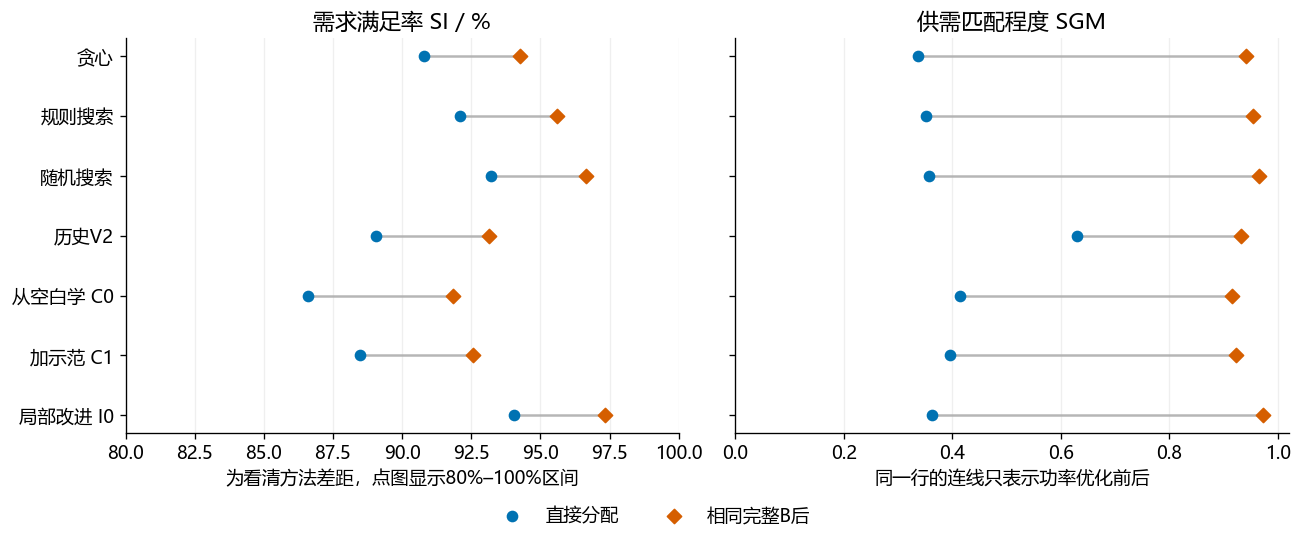

In [7]:
fig, axes = plt.subplots(1,2,figsize=(11,4.3),sharey=True)
y = np.arange(len(order2))
for ax, frame, title, limits in [(axes[0],si2,'需求满足率 SI / %',(80,100)),(axes[1],sgm2,'供需匹配程度 SGM',(0,1.02))]:
    for idx, role in enumerate(order2):
        ax.plot([frame.loc[role,'direct'],frame.loc[role,'final_B']],[idx,idx],color='#b6b6b6',zorder=1)
    ax.scatter(frame.direct,y,color=BLUE,label='直接分配',zorder=2)
    ax.scatter(frame.final_B,y,color=ORANGE,marker='D',label='相同完整B后',zorder=2)
    ax.set_xlim(*limits);ax.set_title(title);ax.grid(axis='x',alpha=.2)
    ax.set_yticks(y,[names2[r] for r in order2])
axes[0].invert_yaxis();axes[0].set_xlabel('为看清方法差距，点图显示80%–100%区间')
axes[1].set_xlabel('同一行的连线只表示功率优化前后')
fig.legend(*axes[0].get_legend_handles_labels(),loc='lower center',bbox_to_anchor=(.5,-.065),ncol=2,frameon=False)
save_show(fig,'02_s2_direct_and_power_refined')

**这张图说明三件事。**

1. C1比C0好，说明教师示范在这对同结构模型中有帮助；但两者仍低于贪心。
2. I0的直接SI约94.05%，同样功率优化后约97.33%；贪心对应90.79%和94.27%。学习改频率槽的收益在功率优化后仍保留。
3. I0直接SGM只有约0.362，功率优化后约0.973。最终的供需匹配改善有很大一部分来自连续功率求解，不能全部记给学习。

更关键的是I0和“也会搜索”的方法比。下面按同景做差：正数表示I0更好；退步景数按880个衍生景计，彼此并非完全独立。

In [8]:
comparisons = []
for stage in ['direct','final_B']:
    pivot = s2[s2.stage.eq(stage)].pivot(index='scene_sha256',columns='role',values='si')
    for baseline in order2[:3]:
        delta = (pivot.I0 - pivot[baseline])*100
        # 正式报告以原SI 1e-8为数值容差；换成百分点就是1e-6。
        comparisons.append(['直接' if stage=='direct' else '同样功率优化后',names2[baseline],delta.mean(),int((delta < -1e-6).sum())])
table(pd.DataFrame(comparisons,columns=['比较阶段','I0相对谁','平均SI提高/百分点','SI退步景数/880']),4)

比较阶段,I0相对谁,平均SI提高/百分点,SI退步景数/880
直接,贪心,3.2609,0
直接,规则搜索,1.9471,115
直接,随机搜索,0.8434,206
同样功率优化后,贪心,3.0658,2
同样功率优化后,规则搜索,1.7490,112
同样功率优化后,随机搜索,0.6847,161


同样完整B后，I0相对随机搜索平均再高约 **0.6847个百分点**。这比“相对贪心高3.0658个百分点”更接近我们要追问的学习额外贡献。
但它只针对这套候选菜单和两个非学习搜索对照；没有比较所有可能的强搜索算法。

最终B之后，I0相对贪心仍有2景SI/SGM退步、3景基本服务束数退步。平均提升不等于每景都提升。
原报告的区间按40母场景重采样，反映本批场景差异，不能当成多个训练种子的稳定性。

时间也有代价：I0需要生成候选和实际试算，不是一次神经网络前向就得到全部结果。
下表给保存记录的单次分配均时；服务器重启、设备和并发条件改变，所以这些数字只能说明成本，**不能证明同一墙钟预算下I0更优**。

In [9]:
time2 = s2.groupby(['role','stage']).total_seconds_mean_per_action.mean().unstack('stage')
chosen = order2[:3]+['I0']
table(pd.DataFrame({'方法':[names2[r] for r in chosen], '直接均时/s':time2.loc[chosen,'direct'].values,
    '含完整B的均时/s':time2.loc[chosen,'final_B'].values}),3)

方法,直接均时/s,含完整B的均时/s
贪心,0.278,6.184
规则搜索,1.152,6.888
随机搜索,1.161,6.567
局部改进 I0,1.199,6.669


P19里，**I0组合路线的平均SI高于本轮从空白构造的C0/C1**，值得继续沿着强初解上的学习局部修改研究。
但它们同时改变了起点、动作、网络和预算单位，不能把差异只归因于“起点更好”或某一种学习方式。
I0对同菜单规则/随机搜索另有平均质量证据；还不能说Transformer已经被证明更好，也不能说速度和每景表现全面胜出。

来源：[P19正式报告15](../第二阶段/实验报告/15_SAC三路线超越贪心的独立场景对照.md)。

## 三、第三阶段：频率槽不动，只把功率调细

这几轮**没有新训练强化学习模型**。它们复用G11的T0固定15万步终点，先生成初解，再用CPU上的数学优化调整功率。
第一轮有三种方法，第二轮扩到七条路线，第三轮专门看SCA之后还有多少提升空间。

每组都有两种功率上限：

- **3000 W**：所有场景都用这个总预算。
- **初始总功率**：每次只允许使用T0初解原本用掉的总量，用来减少“只是多给了功率”的影响。

连续法允许非负整束功率，只受总预算约束；原档位法仍用5–50 W的离散档位。
所以与档位法比较时，改善里同时包含算法、初始化和单束可行范围的变化。

### 第一轮：连续功率有没有用？（S3-P01，10月3日）

Jan25的100景，每景3次动作，对比原分配、原档位调整、SLSQP连续求解。两种预算合计1800条方法结果。

- 3000 W口径：原分配SI **91.5300%**，连续求解 **95.0546%**，提高 **3.5246个百分点**。
- 初始总功率口径：连续求解SI **94.9681%**，仍比原分配高 **3.4381个百分点**。
- 代价和限制：严格达到基本服务门槛的束数下降，有不少求解没有收敛；拿到的是有限预算内的结果，不是全局最优证书。

“基本服务”指每束容量至少达到自身需求的10%。边界附近即使只差很小的浮点数，严格计数也仍要如实报告。

来源：[P01正式报告](../第三阶段/实验报告/01_T0初始解的连续功率细调对照.md)。

### 第二轮：哪条功率路线更划算？（S3-P02，10月3日）

换用Jan26的100景，比较7条路线：原分配、原档位、SLSQP、SCA、差分进化DE、粒子群PSO、速率提议WMMSE。
每景3次动作、两种总功率预算，合计4200条方法结果。各路线的目标和停止条件并非完全一致，结论限于这里的实现和预算。

SCA可以先理解为：每轮把难问题近似成一个较容易求的小问题，反复修正。
下面把效果和时间一起看。时间包含初解、公共准备、求解和最终核验；不是只报优化器内部的那一段。

In [10]:
p02_all, p02_time = read_result('s3_p02'), read_result('s3_p02_time')
order3 = ['none','discrete','slsqp','sca','de','pso','wmmse']
names3 = dict(zip(order3,['原分配','原档位','SLSQP','SCA','差分进化 DE','粒子群 PSO','速率提议 WMMSE']))
p02 = p02_all[p02_all['mode'].eq(POWER_BUDGET)].set_index('method').reindex(order3)
t02 = p02_time[(p02_time['mode']==POWER_BUDGET)&(p02_time.stage=='total_pipeline_seconds')&(p02_time.unit=='single')].set_index('method').reindex(order3)
display(Markdown('**当前图表口径：'+POWER_LABEL+'；100景，每景3次动作，先景内平均。**'))
table(pd.DataFrame({'方法':[names3[r] for r in order3], 'SI/%':p02.final_si_mean.values*100,
    'SGM':p02.final_sgm_mean.values,'严格基本服务束/100':p02.basic_met_count.values,
    '完整均时/s':t02['mean'].values,'中位/s':t02['median'].values,'P95/s':t02.p95.values}),4)

**当前图表口径：3000 W总预算；100景，每景3次动作，先景内平均。**

方法,SI/%,SGM,严格基本服务束/100,完整均时/s,中位/s,P95/s
原分配,89.7898,0.7080,99.6767,0.6630,0.6819,0.7303
原档位,90.0590,0.7108,99.6767,1.0080,1.0516,1.1216
SLSQP,93.7473,0.9378,98.9833,12.0126,11.6616,18.3334
SCA,93.7783,0.9402,99.6033,3.8669,3.8455,4.6045
差分进化 DE,90.6097,0.7288,99.7300,1.2673,1.2706,1.4255
粒子群 PSO,91.4810,0.7547,99.7600,1.7719,1.7477,2.0358
速率提议 WMMSE,90.4854,0.7769,99.6867,0.7975,0.7329,1.2122


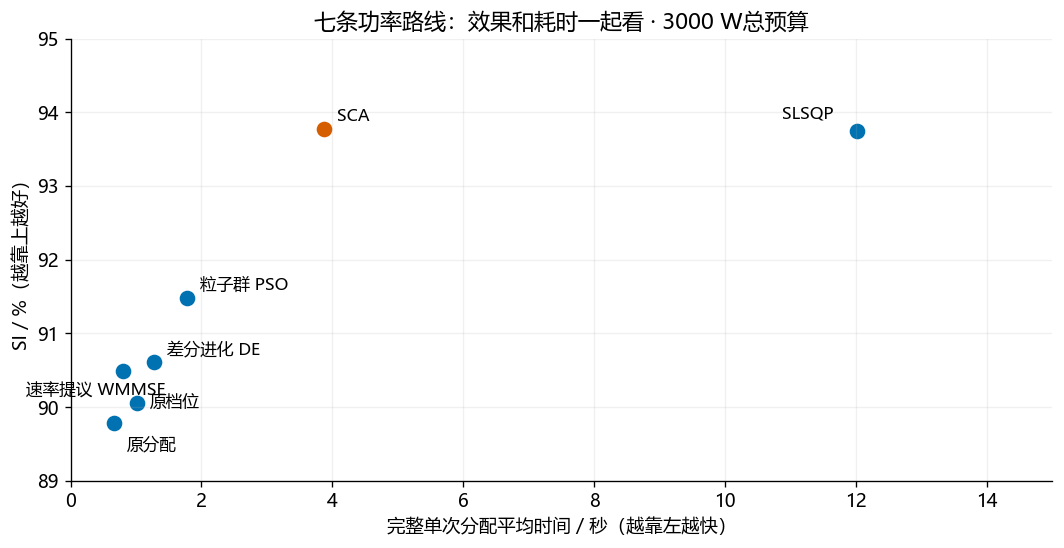

In [11]:
fig,ax = plt.subplots(figsize=(9,4.7))
for method in order3:
    color = ORANGE if method=='sca' else BLUE
    x,y = t02.loc[method,'mean'],p02.loc[method,'final_si_mean']*100
    ax.scatter(x,y,color=color,s=70)
    shift={'none':(8,-16),'discrete':(8,-2),'de':(8,5),'pso':(8,5),'wmmse':(-58,-14),'sca':(8,5),'slsqp':(-45,8)}[method]
    ax.annotate(names3[method],(x,y),xytext=shift,textcoords='offset points',fontsize=10)
ax.set(xlabel='完整单次分配平均时间 / 秒（越靠左越快）',ylabel='SI / %（越靠上越好）',
    title='七条功率路线：效果和耗时一起看 · '+POWER_LABEL,xlim=(0,15),ylim=(89,95))
ax.grid(alpha=.18)
save_show(fig,'03_s3_seven_routes_'+POWER_BUDGET)

3000 W口径下，SCA的SI约93.7783%，SLSQP约93.7473%，很接近；完整均时分别约3.87秒、12.01秒。
所以SCA在这组里是较实用的选择，但不是所有场景都更好，也没有证明全局最优。
严格基本服务仍要另看；较高平均SI不能抵消这项限制。

**不要拿本轮93.78%和上轮95.05%说算法退步了：两轮用的日期和场景不同。**

来源：[P02七路线与耗时报告](../第三阶段/实验报告/02_七路线功率细调与逐场景耗时对照.md)。

### 第三轮：在SCA后继续拧，能再提高多少？（S3-P03，10月3日完成计算，4日交报告）

这次用Jan27的100景。A是原SCA；B、C都从同一个A终点出发，**不是A→B→C串着跑**。

- **A**：原SCA结果。
- **B**：再加一段，先追求SI，再尽量改善SGM。
- **C**：和B相同的目标、相同追加预算，换更精细的容量近似。

B和C各追加最多2000次容量调用、30秒；完整路线要把公共A段计入。
两种预算共1800条结果，没有新增DRL训练。

方法,SI/%,比A提高/百分点,SGM,完整均时/s
A 原SCA,94.224274,0.000000,0.943430,3.915545
B 再追SI,94.225854,0.001581,0.943229,5.529387
C 改容量近似,94.226564,0.002290,0.943162,11.331317


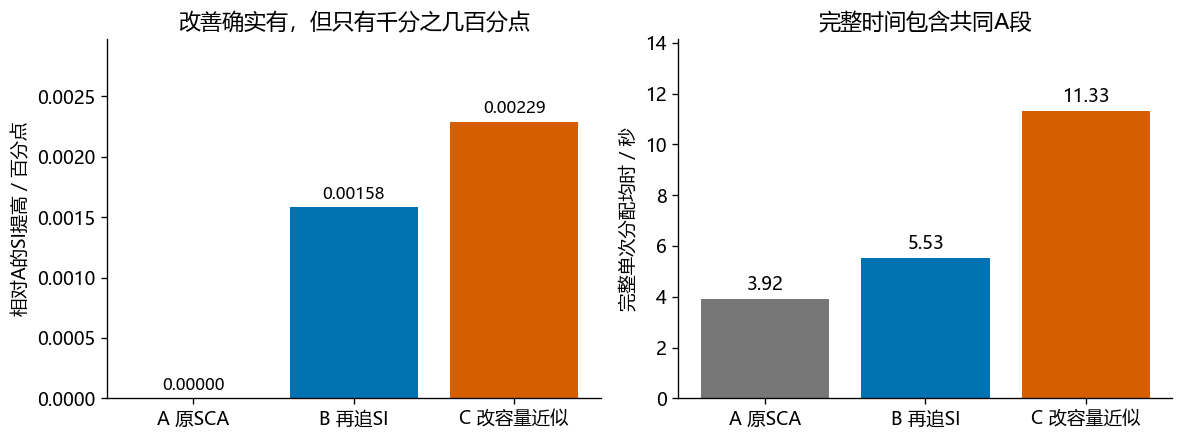

In [12]:
p03_all, p03_time = read_result('s3_p03'), read_result('s3_p03_time')
order4 = ['sca','sca_si_lp','sca_si_lb']; labels4 = ['A 原SCA','B 再追SI','C 改容量近似']
p03 = p03_all[p03_all['mode'].eq(POWER_BUDGET)].set_index('method').reindex(order4)
t03 = p03_time[(p03_time['mode']==POWER_BUDGET)&(p03_time.stage=='total_pipeline_seconds')&(p03_time.unit=='single')].set_index('method').reindex(order4)
gain3 = (p03.final_si_mean-p03.loc['sca','final_si_mean'])*100
table(pd.DataFrame({'方法':labels4,'SI/%':p03.final_si_mean.values*100,'比A提高/百分点':gain3.values,
    'SGM':p03.final_sgm_mean.values,'完整均时/s':t03['mean'].values}),6)
fig, axes = plt.subplots(1,2,figsize=(10,3.8))
b1=axes[0].bar(labels4,gain3,color=[GRAY,BLUE,ORANGE]);axes[0].bar_label(b1,fmt='%.5f',padding=3,fontsize=10)
axes[0].set_ylabel('相对A的SI提高 / 百分点');axes[0].set_title('改善确实有，但只有千分之几百分点')
axes[0].set_ylim(0,max(gain3)*1.3)
b2=axes[1].bar(labels4,t03['mean'],color=[GRAY,BLUE,ORANGE]);axes[1].bar_label(b2,fmt='%.2f',padding=3)
axes[1].set_ylabel('完整单次分配均时 / 秒');axes[1].set_title('完整时间包含共同A段')
axes[1].set_ylim(0,max(t03['mean'])*1.25)
save_show(fig,'04_s3_extra_refinement_'+POWER_BUDGET)

在3000 W口径下，B比A高 **0.00158个百分点**，C比A高 **0.00229个百分点**。
不是0.158或0.229个百分点。完整均时却从约3.92秒增加到5.53秒和11.33秒，SGM还略降。

换用“初始总功率上限”后，B/C的SI增量也只有约0.00171/0.00248个百分点，结论相近。
这支持“在这批固定槽场景和给定求解预算下，继续细调的收益已经很小”；**不支持“已经达到物理上限”。**

后来第二阶段P17/P19说的“完整B”，就是把SCA及SI优先追加段作为统一的功率处理流程。
它是第三阶段方法在新初解上的使用，不是又训练了一个功率网络。每个初解的原分配/A/B三条记录，也不等于三次完整B。

来源：[P03正式报告](../第三阶段/实验报告/03_SI优先功率细调与容量近似对照.md)。

## 四、现在能把研究进展讲到哪一步

| 可以直接讲的 | 还不能这样讲 |
|---|---|
| 第一阶段做过从位置微调到区域重构、可变束数、教师示范和PPO的多轮对照 | “PPO已经全面超过强规则”“指向、宽度、动态已经全部完成” |
| 第二阶段I0在本批新场景、同菜单对照下，有平均质量收益 | “Transformer已经证明最好”“每个场景都更好”“同样时间预算下一定更优” |
| 第三阶段连续优化明显改善过固定槽初解，SCA在七路线中效果/耗时较合适 | “得到全局最优功率”“继续细调没收益，所以已到容量上限” |
| 当前方法分工更明确：学习改离散结构，数学优化调连续功率 | “完整三阶段已经用同一批场景验证完毕” |

如果向导师用三句话汇报，可以这样说：

> 覆盖阶段已经能做出可行布局，但最新实验里PPO的额外收益还不够，BC和强规则仍是重要参照。  
> 频率阶段从“从头分配”转向“在贪心解上学习局部修改”，在新场景和相同搜索菜单下得到了平均收益。  
> 功率阶段用连续优化能改善服务，SCA较实用；继续追加优化的收益较小，不能把它说成已经全局最优。

### 自己核对一个容易说错的比较

I0＋完整B约97.33%，未调功率的贪心约90.79%。两者差约6.54个百分点，能不能都算作学习的贡献？

<details><summary>展开看解释</summary>

不能。这一差值混进了功率优化的作用。应该先看“直接I0对直接贪心”（约+3.2609个百分点），
再看“都做完整B之后”（约+3.0658个百分点）。若进一步追问学习相对搜索的作用，还要和同菜单规则/随机搜索比较。
本轮同完整B之后，I0相对随机搜索的平均SI优势约0.6847个百分点。

</details>

## 五、需要回查时，从这里进

这份导读没有重跑模型，图表来自现有逐场景结果或正式报告的保存汇总。历史段落引用各组正式报告；
当前状态按已归档的完成证据整理，本次没有重新登录远端查询活跃进程。

- [实验状态入口](../../EXPERIMENT_STATUS.md)：先看页首最新更正，后面保留了很多历史快照。
- [第一阶段目录](../第一阶段/00_目录.md)、[第二阶段目录](../第二阶段/00_目录.md)、[第三阶段目录](../第三阶段/00_目录.md)。
- [完整历史讨论版06](06_中期研究进展与路线调整_导师讨论版.md)：想看9月更早的奖励、掩码、网络和状态实验时查这里。
- [正式中期报告07](07_HTS资源分配中期报告_正式版.md)：学术正文示例；成文早于S1-D12A最终交付，不把其当作最新第一阶段效果入口。

**怎么重跑：**在本项目的Jupyter/VS Code中打开此文件，使用有 pandas、NumPy、Matplotlib、IPython 的Python环境，从头执行。
无需PyTorch或GPU。已执行的图片和表格嵌入笔记本；仅阅读无需重新运行。
来源CSV必须仍在原位置且SHA一致，发现文件变动会报错，不会静默拿新数据冒充旧结果。

下面列出实际读取的7份数据文件。CSV只读；图表和检查记录存到 `outputs/research_overview_20261012/`。

In [13]:
source_rows = [{'用途':key,'项目内路径':value,'SHA256前12位':EXPECTED_SHA[key][:12]} for key,value in SOURCES.items()]
table(pd.DataFrame(source_rows))
checks = {'s1_test_rows':len(s1),'s1_mothers_per_method':100,'s2_rows_per_method_stage':880,'s2_mothers':40,
    's1_cv_P0_relative_H1_pct':float((s1_mean.loc['P0','load_cv']/s1_mean.loc['H1','load_cv']-1)*100),
    's1_cv_P1_relative_H1_pct':float((s1_mean.loc['P1','load_cv']/s1_mean.loc['H1','load_cv']-1)*100),
    's2_I0_vs_greedy_direct_pp':float(si2.loc['I0','direct']-si2.loc[order2[0],'direct']),
    's2_I0_vs_greedy_B_pp':float(si2.loc['I0','final_B']-si2.loc[order2[0],'final_B']),
    'power_budget':POWER_BUDGET,'s3_B_vs_A_pp':float(gain3.iloc[1]),'s3_C_vs_A_pp':float(gain3.iloc[2]),
    'python':sys.version.split()[0], 'pandas':pd.__version__,'matplotlib':__import__('matplotlib').__version__,
    'sources':SOURCES,'source_sha256':EXPECTED_SHA,'new_training':False,'new_environment_evaluation':False}
(OUT/'numeric_checks.json').write_text(json.dumps(checks,ensure_ascii=False,indent=2),encoding='utf-8')
print('各数据完整性检查通过；本笔记本没有新增训练或环境评价。')

用途,项目内路径,SHA256前12位
s1,outputs/experiments/first_stage_s1_d12a_20261010/analysis/final_report_verified/per_scene.csv,d444cc498cb4
s1_published,outputs/experiments/first_stage_s1_d12a_20261010/analysis/publication/overall_100_mothers.csv,2c678379a6f2
s2,outputs/experiments/sac_routes_s2p19_20261007/analysis/final_report_material/per_scene.csv,1a76c4c3f362
s3_p02,outputs/experiments/stage3_all_routes_20261003/report_20261003/method_summary.csv,41e2840be436
s3_p02_time,outputs/experiments/stage3_all_routes_20261003/report_20261003/timing_summary.csv,9436834ef5b3
s3_p03,outputs/experiments/stage3_si_priority_20261003/report_20261003/method_summary.csv,bd29530ed2b7
s3_p03_time,outputs/experiments/stage3_si_priority_20261003/report_20261003/timing_summary.csv,0a6f550e6ba5


各数据完整性检查通过；本笔记本没有新增训练或环境评价。


<details><summary>制作工具说明</summary>

使用 Jupyter Notebook skill 组织可执行文档，使用 scientific-visualization 的图表规范检查单位、尺度和原始数据来源。
工具文献：Kassis, T., Agarwal, V., He, Y., Patel, D., & Brueckner, A. M. (2026).
[Scientific Agent Skills: A Library of Procedural Knowledge for Research Agents](https://doi.org/10.48550/arXiv.2609.00065)。
这是工具出处，不是上述卫星实验结论的来源。

</details>